In [3]:
import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load WT data (4 replicates, 2 methods each)
wt_dfs = []
for rep in range(0, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    wt_dfs.append(wb_df)

T419R_dfs = []
for rep in range(1, 2):
    wb_df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    T419R_dfs.append(wb_df)

In [5]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['sele1_index', 'sele2_index', 'sele1_resid', 
                               'sele2_resid', 'sele1_resnm', 'sele2_resnm']).size().reset_index(name='count')

    agg_df['group'] = label
    return agg_df

In [6]:

wt_agg = aggregate_hbonds(wt_dfs, 'wt')
mut_agg = aggregate_hbonds(T419R_dfs, 'T419R')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([wt_agg, mut_agg])

Number of rows per time value:
time
100000.0     5
100100.0    12
100300.0     8
100500.0     2
100600.0     3
            ..
199600.0     8
199700.0     8
199800.0     3
199900.0     6
200000.0     4
Name: count, Length: 937, dtype: int64
Number of rows per time value:
time
100000.0    1
100100.0    1
100200.0    1
100400.0    1
100500.0    3
           ..
199400.0    4
199600.0    1
199700.0    5
199800.0    3
199900.0    4
Name: count, Length: 698, dtype: int64


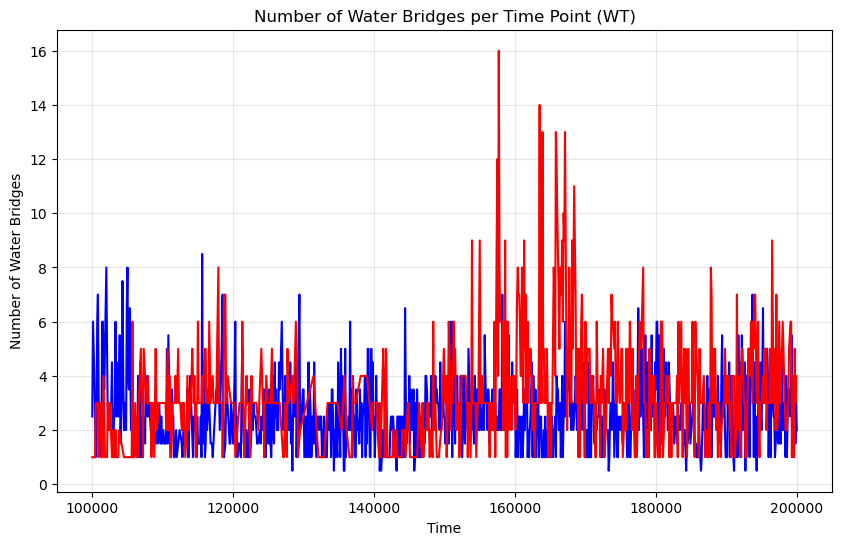

In [7]:
combined_wt = pd.concat(wt_dfs)
# Count rows per unique time value
time_counts_wt = combined_wt['time'].value_counts().sort_index()

# Print the results
print("Number of rows per time value:")
print(time_counts_wt)

combined_mut = pd.concat(T419R_dfs)
# Count rows per unique time value
time_counts_mut = combined_mut['time'].value_counts().sort_index()

# Print the results
print("Number of rows per time value:")
print(time_counts_mut)

# Optionally, plot the results
plt.figure(figsize=(10, 6))
plt.plot(time_counts_wt.index, time_counts_wt.values/2, color='blue')
plt.plot(time_counts_mut.index, time_counts_mut.values, color='red')
plt.xlabel('Time')
plt.ylabel('Number of Water Bridges')
plt.title('Number of Water Bridges per Time Point (WT)')
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
all_hbonds.sort_values('count', ascending=False).head()

,sele1_index,sele2_index,sele1_resid,sele2_resid,sele1_resnm,sele2_resnm,count,group
494,14152,19732,283,6,ARG,DA,703,wt
613,14155,19732,283,6,ARG,DA,651,wt
298,14186,19752,284,6,ARG,DA,213,T419R
70,4763,18992,284,5,ARG,DA,126,T419R
17,4762,38113,284,5028,ARG,WAT,81,T419R


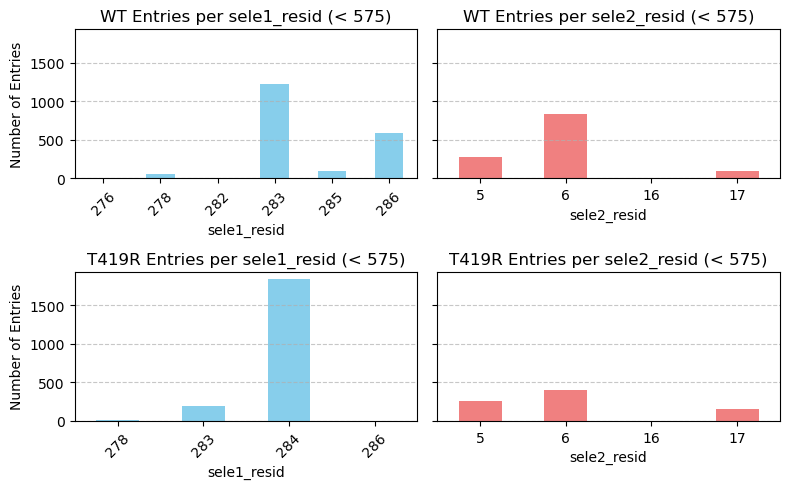

Counts per sele1_resid (< 575):
sele1_resid
278      13
283     187
284    1840
286       1
Name: count, dtype: int64

Counts per sele2_resid (< 575):
sele2_resid
5     258
6     397
16      1
17    159
Name: count, dtype: int64


In [9]:
combined_wt = pd.concat(wt_dfs)
# Filter for < 1000
sele1_filtered = combined_wt[combined_wt["sele1_resid"] < 575]
sele2_filtered = combined_wt[combined_wt["sele2_resid"] < 575]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid"].value_counts().sort_index()/2
sele2_counts = sele2_filtered["sele2_resid"].value_counts().sort_index()/2

# Create side-by-side subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Plot sele1_resid
sele1_counts.plot(kind="bar", color="skyblue", ax=ax1)
ax1.set_xlabel("sele1_resid")
ax1.set_ylabel("Number of Entries")
ax1.set_title("WT Entries per sele1_resid (< 575)")
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.tick_params(axis="x", rotation=45)

# Plot sele2_resid
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax2)
ax2.set_xlabel("sele2_resid")
ax2.set_title("WT Entries per sele2_resid (< 575)")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
ax2.tick_params(axis="x", rotation=0)

combined_T419R = pd.concat(T419R_dfs)
# Filter for < 1000
sele1_filtered = combined_T419R[combined_T419R["sele1_resid"] < 575]
sele2_filtered = combined_T419R[combined_T419R["sele2_resid"] < 575]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid"].value_counts().sort_index()
sele2_counts = sele2_filtered["sele2_resid"].value_counts().sort_index()

# Plot sele1_resid
sele1_counts.plot(kind="bar", color="skyblue", ax=ax3)
ax3.set_xlabel("sele1_resid")
ax3.set_ylabel("Number of Entries")
ax3.set_title("T419R Entries per sele1_resid (< 575)")
ax3.grid(axis="y", linestyle="--", alpha=0.7)
ax3.tick_params(axis="x", rotation=45)

# Plot sele2_resid
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax4)
ax4.set_xlabel("sele2_resid")
ax4.set_title("T419R Entries per sele2_resid (< 575)")
ax4.grid(axis="y", linestyle="--", alpha=0.7)
ax4.tick_params(axis="x", rotation=0)

# Adjust layout
plt.tight_layout()
plt.show()

# Print counts for reference
print("Counts per sele1_resid (< 575):")
print(sele1_counts)
print("\nCounts per sele2_resid (< 575):")
print(sele2_counts)